# Implementation 3: Practical Applications of SOR

**Math 455 Midterm Project: Relaxation Methods**

The textbook says SOR is "particularly useful for solving the linear systems that occur in the numerical
solution of certain partial-differential equations" (p. 470), and Section 12.1 recommends Algorithm 7.3 for
large systems of that kind. This notebook applies SOR to three differential equations from the textbook,
each with published answers to test against:

1. **A boundary value problem** (Section 11.3, Example 1). This is the finite-difference method from the
   Homework 3 notes (§3.3), which leads to a tridiagonal system.
2. **Steady-state heat in a metal plate** (Section 12.1, Example 1). Laplace's equation leads to a 9 × 9 system.
3. **A Poisson equation** (Section 12.1, Example 2), with unequal grid spacing in $x$ and $y$.

It ends with a **scaling study**: the plate problem on finer and finer grids, which is where SOR's advantage
over Gauss-Seidel becomes large. Two figures for the report are saved to `figures/`.

In [1]:
import contextlib
import io
import os
from collections import namedtuple

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap

os.makedirs("figures", exist_ok=True)

## Tools from Implementations 1 and 2

`sor` (Algorithm 7.3) and the iteration-matrix helpers are copied unchanged from the earlier notebooks.
`optimal_omega` is the Theorem 7.26 formula $\omega = 2/\big(1 + \sqrt{1 - \rho(T_J)^2}\big)$.

In [2]:
SORResult = namedtuple("SORResult", ["x", "iterations", "converged", "history"])


def sor(A, b, x0, omega, tol, max_iter, norm=np.inf):
    '''Solve Ax = b by SOR (Burden, Faires & Burden, Algorithm 7.3).

    Returns SORResult(x, iterations, converged, history), where history[k] is
    the iterate x^(k) and history[0] is x0.
    '''
    A = np.asarray(A, dtype=float)
    b = np.asarray(b, dtype=float)
    XO = np.array(x0, dtype=float)
    n = len(b)

    if np.any(np.diag(A) == 0):
        raise ValueError("SOR requires every diagonal entry a_ii to be nonzero")

    x = np.zeros(n)
    history = [XO.copy()]

    k = 1                                                     # Step 1
    while k <= max_iter:                                      # Step 2
        for i in range(n):                                    # Step 3
            x[i] = (1 - omega) * XO[i] + (1 / A[i, i]) * (
                omega * (-A[i, :i] @ x[:i] - A[i, i + 1:] @ XO[i + 1:] + b[i])
            )
        history.append(x.copy())

        if np.linalg.norm(x - XO, norm) < tol:                # Step 4
            return SORResult(x.copy(), k, True, history)

        k += 1                                                # Step 5
        XO = x.copy()                                         # Step 6

    print("Maximum number of iterations exceeded")            # Step 7
    return SORResult(x.copy(), max_iter, False, history)

In [3]:
def split(A):
    '''Return D, L, U with A = D + L + U (class convention).'''
    A = np.asarray(A, dtype=float)
    return np.diag(np.diag(A)), np.tril(A, -1), np.triu(A, 1)


def jacobi_matrix(A):
    D, L, U = split(A)
    return -np.linalg.solve(D, L + U)


def sor_matrix(A, omega):
    D, L, U = split(A)
    return np.linalg.solve(D + omega * L, (1 - omega) * D - omega * U)


def sor_vector(A, b, omega):
    D, L, U = split(A)
    return omega * np.linalg.solve(D + omega * L, np.asarray(b, dtype=float))


def spectral_radius(T):
    return np.max(np.abs(np.linalg.eigvals(T)))


def optimal_omega(A):
    '''Theorem 7.26: optimal omega for a positive definite tridiagonal matrix.'''
    return 2 / (1 + np.sqrt(1 - spectral_radius(jacobi_matrix(A)) ** 2))

## Application 1: A boundary value problem (Section 11.3, Example 1)

$$y'' = -\frac{2}{x}y' + \frac{2}{x^2}y + \frac{\sin(\ln x)}{x^2}, \qquad 1 \le x \le 2, \qquad y(1) = 1,\; y(2) = 2.$$

This has the form $y'' = p(x)y' + q(x)y + r(x)$. As in the Homework 3 notes (§3.3), replace $y''$ and $y'$ by
centered differences on a grid $x_i = a + ih$, with $h = (b-a)/(N+1)$. Multiplying by $-h^2$ gives, for
$i = 1, \dots, N$,

$$-\Big(1 + \tfrac{h}{2}p(x_i)\Big)w_{i-1} + \big(2 + h^2 q(x_i)\big)w_i - \Big(1 - \tfrac{h}{2}p(x_i)\Big)w_{i+1} = -h^2 r(x_i),$$

with the known boundary values $w_0 = y(a)$ and $w_{N+1} = y(b)$ moved to the right-hand side. This is the
textbook's form (Eq. 11.19). The notes write the same equation multiplied by $-1$. The system is
tridiagonal, the type the Crout method from Homework 3 solves directly.

In [4]:
def bvp_system(p, q, r, a, b, alpha, beta, N):
    '''Finite-difference system for y'' = p y' + q y + r, y(a) = alpha, y(b) = beta (Eq. 11.19).'''
    h = (b - a) / (N + 1)
    x = a + h * np.arange(1, N + 1)
    A = (np.diag(2 + h**2 * q(x))
         + np.diag(-1 + h / 2 * p(x[:-1]), 1)
         + np.diag(-1 - h / 2 * p(x[1:]), -1))
    rhs = -h**2 * r(x)
    rhs[0] += (1 + h / 2 * p(x[0])) * alpha
    rhs[-1] += (1 - h / 2 * p(x[-1])) * beta
    return x, A, rhs


x_bvp, A_bvp, b_bvp = bvp_system(p=lambda x: -2 / x,
                                 q=lambda x: 2 / x**2,
                                 r=lambda x: np.sin(np.log(x)) / x**2,
                                 a=1, b=2, alpha=1, beta=2, N=9)


def y_exact(x):
    '''Exact solution, from Section 11.1, Example 2.'''
    c2 = (8 - 12 * np.sin(np.log(2)) - 4 * np.cos(np.log(2))) / 70
    c1 = 11 / 10 - c2
    return c1 * x + c2 / x**2 - 3 / 10 * np.sin(np.log(x)) - 1 / 10 * np.cos(np.log(x))


# Table 11.3: the finite-difference values w_i and the exact values y(x_i), for x = 1.1, ..., 1.9
TABLE_11_3_W = [1.09260052, 1.18704313, 1.28333687, 1.38140205, 1.48112026,
                1.58235990, 1.68498902, 1.78888175, 1.89392110]
TABLE_11_3_Y = [1.09262930, 1.18708484, 1.28338236, 1.38144595, 1.48115942,
                1.58239246, 1.68501396, 1.78889853, 1.89392951]

print(f"{len(b_bvp)} unknowns, h = {x_bvp[1] - x_bvp[0]:.1f}")

9 unknowns, h = 0.1


### Test 1: SOR reproduces Table 11.3

The book solves this system directly (with Crout factorization). SOR must give the same $w_i$, to the 8
decimal places printed. The matrix is strictly diagonally dominant (Homework 3 notes, §3.1), which guarantees
that Jacobi and Gauss-Seidel converge.

The matrix is **not** symmetric, so Theorem 7.26 does not formally apply. It is tridiagonal, though, and
its Jacobi matrix has real eigenvalues, so the same formula for the best $\omega$ still holds (a result of
Young's theory, beyond our course). The test checks this numerically.

In [5]:
def is_sdd(A):
    off_diagonal = np.sum(np.abs(A), axis=1) - np.abs(np.diag(A))
    return np.all(np.abs(np.diag(A)) > off_diagonal)


assert is_sdd(A_bvp) and not np.allclose(A_bvp, A_bvp.T)
assert np.allclose(np.linalg.eigvals(jacobi_matrix(A_bvp)).imag, 0)

w_bvp = optimal_omega(A_bvp)
fine = np.arange(0.5, 2.0, 0.001)
w_numeric = fine[np.argmin([spectral_radius(sor_matrix(A_bvp, w)) for w in fine])]
assert abs(w_bvp - w_numeric) <= 0.001

gs_bvp = sor(A_bvp, b_bvp, np.zeros(9), omega=1.0, tol=1e-12, max_iter=10_000)
sor_bvp = sor(A_bvp, b_bvp, np.zeros(9), omega=w_bvp, tol=1e-12, max_iter=10_000)

for result in [gs_bvp, sor_bvp]:
    assert result.converged
    assert np.max(np.abs(result.x - TABLE_11_3_W)) <= 0.5e-8 + 1e-12
assert np.max(np.abs(y_exact(x_bvp) - TABLE_11_3_Y)) <= 0.5e-8 + 1e-12

print(f"rho(T_J) = {spectral_radius(jacobi_matrix(A_bvp)):.4f}; "
      f"best omega: formula {w_bvp:.4f}, numerical search {w_numeric:.3f}")
print(f"Gauss-Seidel: {gs_bvp.iterations} iterations; SOR (omega = {w_bvp:.4f}): {sor_bvp.iterations} iterations")
print(f"Largest |w_i - y(x_i)| (discretization error): {np.max(np.abs(sor_bvp.x - y_exact(x_bvp))):.2e}")
print("PASS: both methods reproduce Table 11.3, and the exact solution matches the book's y(x_i)")

rho(T_J) = 0.9467; best omega: formula 1.5126, numerical search 1.513


Gauss-Seidel: 241 iterations; SOR (omega = 1.5126): 51 iterations
Largest |w_i - y(x_i)| (discretization error): 4.55e-05
PASS: both methods reproduce Table 11.3, and the exact solution matches the book's y(x_i)


SOR needs about a fifth of Gauss-Seidel's iterations here. Both are solved to $TOL = 10^{-12}$, but the
finite-difference answer itself is only accurate to about $4.6 \times 10^{-5}$ (the discretization error in
Table 11.3). In practice, the iteration only needs to be accurate to well below that error: solving the
linear system more precisely does not make $w_i$ a better approximation of $y(x_i)$.

## The Poisson equation on a rectangle (Section 12.1)

Applications 2 and 3 both solve

$$\frac{\partial^2 u}{\partial x^2} + \frac{\partial^2 u}{\partial y^2} = f(x, y), \quad a < x < b,\; c < y < d,
\qquad u = g \text{ on the boundary}.$$

With $n$ steps of size $h$ in $x$ and $m$ steps of size $k$ in $y$, and $\lambda = h^2/k^2$, the
finite-difference equation at each interior grid point (Eq. 12.4, multiplied by $h^2$) is

$$2(1 + \lambda)\,w_{i,j} - (w_{i+1,j} + w_{i-1,j}) - \lambda\,(w_{i,j+1} + w_{i,j-1}) = -h^2 f(x_i, y_j).$$

The unknowns are numbered left to right, top row first: $l = i + (m - 1 - j)(n - 1)$ (p. 736). Values on the
boundary are known and move to the right-hand side. Each equation involves at most 5 unknowns, so the matrix
is mostly zeros: a *sparse* matrix, in the language of the Homework 3 notes.

In [6]:
def poisson_system(f, g, a, b, c, d, n, m):
    '''Finite-difference system for u_xx + u_yy = f with u = g on the boundary (Section 12.1).

    Returns the matrix, the right-hand side, and the grid coordinates (X, Y) of each unknown.
    '''
    h, k = (b - a) / n, (d - c) / m
    lam = h**2 / k**2
    size = (n - 1) * (m - 1)
    A = np.zeros((size, size))
    rhs = np.zeros(size)
    X, Y = np.zeros(size), np.zeros(size)

    def label(i, j):
        return (i - 1) + (m - 1 - j) * (n - 1)  # p. 736, shifted to start at 0

    for j in range(1, m):
        for i in range(1, n):
            l = label(i, j)
            X[l], Y[l] = a + i * h, c + j * k
            A[l, l] = 2 * (1 + lam)
            rhs[l] = -h**2 * f(X[l], Y[l])
            for ii, jj, weight in [(i + 1, j, 1), (i - 1, j, 1), (i, j + 1, lam), (i, j - 1, lam)]:
                if 1 <= ii <= n - 1 and 1 <= jj <= m - 1:
                    A[l, label(ii, jj)] = -weight
                else:
                    rhs[l] += weight * g(a + ii * h, c + jj * k)
    return A, rhs, X, Y

## Application 2: Heat in a metal plate (Section 12.1, Example 1)

A 0.5 m × 0.5 m plate has two adjacent edges held at 0°C. On the other two edges the temperature rises
linearly from 0°C to 100°C at the corner where they meet. The steady-state temperature satisfies Laplace's
equation ($f = 0$) with

$$u(0, y) = 0, \quad u(x, 0) = 0, \quad u(x, 0.5) = 200x, \quad u(0.5, y) = 200y.$$

The exact solution is $u(x, y) = 400xy$. Its fourth derivatives are zero, so the finite-difference method
has no truncation error and Table 12.1 gives the exact temperatures.

In [7]:
def plate_boundary(x, y):
    if np.isclose(y, 0.5):
        return 200 * x
    if np.isclose(x, 0.5):
        return 200 * y
    return 0.0


def plate_system(n):
    '''The Example 1 plate on an n-by-n grid (h = k = 0.5 / n).'''
    return poisson_system(lambda x, y: 0.0, plate_boundary, 0, 0.5, 0, 0.5, n, n)


A_plate, b_plate, X_plate, Y_plate = plate_system(4)

# The matrix and right-hand side printed on p. 737
BOOK_MATRIX = np.array([
    [4, -1, 0, -1, 0, 0, 0, 0, 0],
    [-1, 4, -1, 0, -1, 0, 0, 0, 0],
    [0, -1, 4, 0, 0, -1, 0, 0, 0],
    [-1, 0, 0, 4, -1, 0, -1, 0, 0],
    [0, -1, 0, -1, 4, -1, 0, -1, 0],
    [0, 0, -1, 0, -1, 4, 0, 0, -1],
    [0, 0, 0, -1, 0, 0, 4, -1, 0],
    [0, 0, 0, 0, -1, 0, -1, 4, -1],
    [0, 0, 0, 0, 0, -1, 0, -1, 4],
])
BOOK_RHS = [25, 50, 150, 0, 0, 50, 0, 0, 25]
TABLE_12_1 = [18.75, 37.50, 56.25, 12.50, 25.00, 37.50, 6.25, 12.50, 18.75]

### Test 2: The plate system and its solution

The assembled system must equal the one printed on p. 737, and SOR must reproduce Table 12.1. The matrix is
symmetric positive definite, so by Theorem 7.25 SOR converges for every $0 < \omega < 2$.

For an $n \times n$ grid with $h = k$, Section 12.1 (p. 740) gives the Jacobi spectral radius in closed form:
$\rho(T_J) = \cos(\pi/n)$. The test checks this against the eigenvalues too.

In [8]:
assert np.array_equal(A_plate, BOOK_MATRIX) and np.allclose(b_plate, BOOK_RHS)
assert np.allclose(A_plate, A_plate.T) and np.all(np.linalg.eigvalsh(A_plate) > 0)  # positive definite
assert abs(spectral_radius(jacobi_matrix(A_plate)) - np.cos(np.pi / 4)) < 1e-12

w_plate = optimal_omega(A_plate)
plate = sor(A_plate, b_plate, np.zeros(9), omega=w_plate, tol=1e-12, max_iter=1000)
assert plate.converged and np.allclose(plate.x, TABLE_12_1, atol=1e-10)
assert np.allclose(plate.x, 400 * X_plate * Y_plate, atol=1e-10)

gs_plate = sor(A_plate, b_plate, np.zeros(9), omega=1.0, tol=1e-12, max_iter=1000)
print(f"Gauss-Seidel: {gs_plate.iterations} iterations; SOR (omega = {w_plate:.4f}): {plate.iterations} iterations")
print("PASS: the system matches p. 737, and SOR reproduces Table 12.1 (= 400xy)")

Gauss-Seidel: 46 iterations; SOR (omega = 1.1716): 22 iterations
PASS: the system matches p. 737, and SOR reproduces Table 12.1 (= 400xy)


## Application 3: A Poisson equation with unequal spacing (Section 12.1, Example 2)

$$\frac{\partial^2 u}{\partial x^2} + \frac{\partial^2 u}{\partial y^2} = xe^y, \quad 0 < x < 2,\; 0 < y < 1,
\qquad u = xe^y \text{ on the boundary},$$

with $n = 6$ and $m = 5$, so $h = 1/3$ and $k = 1/5$. The book solves it with Algorithm 12.1, which is
Gauss-Seidel sweeping the grid in the same order as our numbering, from a zero starting vector and with
$TOL = 10^{-10}$. The book reports that it **stops at iteration 61**, and Table 12.2 lists the results.

### Test 3: Reproduce Algorithm 12.1, then improve on it

Running `sor` with $\omega = 1$ on the assembled system must stop at the same iteration and give the same
values. The table entries are printed to 5 significant figures, so each is compared to within half a unit
in its last digit.

In [9]:
A_pois, b_pois, X_pois, Y_pois = poisson_system(lambda x, y: x * np.exp(y), lambda x, y: x * np.exp(y),
                                                0, 2, 0, 1, n=6, m=5)

# Table 12.2: (x_i, y_j, w_ij) as printed
TABLE_12_2 = [
    (1, 1, "0.40726"), (1, 2, "0.49748"), (1, 3, "0.60760"), (1, 4, "0.74201"),
    (2, 1, "0.81452"), (2, 2, "0.99496"), (2, 3, "1.2152"), (2, 4, "1.4840"),
    (3, 1, "1.2218"), (3, 2, "1.4924"), (3, 3, "1.8227"), (3, 4, "2.2260"),
    (4, 1, "1.6290"), (4, 2, "1.9898"), (4, 3, "2.4302"), (4, 4, "2.9679"),
    (5, 1, "2.0360"), (5, 2, "2.4870"), (5, 3, "3.0375"), (5, 4, "3.7097"),
]

gs_pois = sor(A_pois, b_pois, np.zeros(20), omega=1.0, tol=1e-10, max_iter=100)
assert gs_pois.converged and gs_pois.iterations == 61

for i, j, printed in TABLE_12_2:
    l = (i - 1) + (5 - 1 - j) * (6 - 1)
    decimals = len(printed.split(".")[1])
    assert abs(gs_pois.x[l] - float(printed)) <= 0.5 * 10.0**-decimals + 1e-12, (i, j)

w_pois = optimal_omega(A_pois)
sor_pois = sor(A_pois, b_pois, np.zeros(20), omega=w_pois, tol=1e-10, max_iter=100)
assert sor_pois.converged and np.max(np.abs(sor_pois.x - gs_pois.x)) < 1e-8

print(f"Gauss-Seidel (Algorithm 12.1): {gs_pois.iterations} iterations (book: 61)")
print(f"SOR (omega = {w_pois:.4f}): {sor_pois.iterations} iterations")
print("PASS: matches the book's iteration count and all 20 entries of Table 12.2")

Gauss-Seidel (Algorithm 12.1): 61 iterations (book: 61)
SOR (omega = 1.2768): 24 iterations
PASS: matches the book's iteration count and all 20 entries of Table 12.2


### The book's formula for $\omega$ assumes $h = k$

Section 12.1 (p. 740) gives $\rho(T_J) = \tfrac12\big[\cos(\pi/m) + \cos(\pi/n)\big]$ for this problem. That
formula holds when $h = k$, as in the plate example. Here $h = 1/3$ and $k = 1/5$, and the weights
$\lambda = h^2/k^2 = 25/9$ on the vertical neighbours change the answer to

$$\rho(T_J) = \frac{\cos(\pi/n) + \lambda\cos(\pi/m)}{1 + \lambda},$$

which reduces to the book's formula when $\lambda = 1$. The check below compares both formulas with the
eigenvalues, and compares SOR's iteration count with the book's $\omega$ against the true optimum.

In [10]:
lam = (1 / 3) ** 2 / (1 / 5) ** 2
rho_eigen = spectral_radius(jacobi_matrix(A_pois))
rho_book = (np.cos(np.pi / 5) + np.cos(np.pi / 6)) / 2
rho_general = (np.cos(np.pi / 6) + lam * np.cos(np.pi / 5)) / (1 + lam)
w_book = 2 / (1 + np.sqrt(1 - rho_book**2))

assert abs(rho_general - rho_eigen) < 1e-12 and abs(rho_book - rho_eigen) > 0.01

sor_book_w = sor(A_pois, b_pois, np.zeros(20), omega=w_book, tol=1e-10, max_iter=100)
print(f"rho(T_J): eigenvalues {rho_eigen:.4f}, general formula {rho_general:.4f}, book's formula {rho_book:.4f}")
print(f"omega: true optimum {w_pois:.4f} ({sor_pois.iterations} iterations), "
      f"book's formula {w_book:.4f} ({sor_book_w.iterations} iterations)")

rho(T_J): eigenvalues 0.8241, general formula 0.8241, book's formula 0.8375
omega: true optimum 1.2768 (24 iterations), book's formula 1.2933 (23 iterations)


The book's formula overestimates the optimal $\omega$ here, but that costs nothing: it even needs one
iteration fewer. Above the optimum, $\rho(T_\omega) = \omega - 1$ grows only linearly, while below it
$\rho(T_\omega)$ rises steeply (Figure 1 in Implementation 2). So when $\omega$ can only be estimated, it is
safer to err on the high side. On a system this small, the first few iterations matter as much as the
asymptotic rate, which is why the count can come out slightly lower.

## Scaling study: the plate on finer grids

Real problems use much finer grids than $4 \times 4$. With $n$ steps per side, the plate has $(n-1)^2$
unknowns, and $\rho(T_J) = \cos(\pi/n)$ creeps toward 1 as $n$ grows. Gauss-Seidel's spectral radius is
$\cos^2(\pi/n) \approx 1 - \pi^2/n^2$, so its iteration count grows like $n^2$. With the optimal $\omega$, SOR's
spectral radius is $\omega - 1 \approx 1 - 2\pi/n$, so its count grows only like $n$.

Each grid is solved by Gauss-Seidel and by SOR with the optimal $\omega$, using Algorithm 7.3's own stopping
rule with $TOL = 10^{-8}$. Since the exact solution is $400xy$ on every grid, the answers can be checked
exactly. This cell takes about 15 seconds, almost all of it Gauss-Seidel on the finest grid.

In [11]:
GRIDS = [4, 8, 16, 32]
SCALING = []

print(f"{'n':>3} {'unknowns':>9} {'omega':>8} {'G-S':>6} {'SOR':>6} {'ratio':>6} {'max error':>10}")
for n in GRIDS:
    A, rhs, X, Y = plate_system(n)
    omega = 2 / (1 + np.sin(np.pi / n))  # optimal_omega with rho(T_J) = cos(pi/n)
    assert abs(omega - optimal_omega(A)) < 1e-9
    gs = sor(A, rhs, np.zeros(len(rhs)), omega=1.0, tol=1e-8, max_iter=20_000)
    sr = sor(A, rhs, np.zeros(len(rhs)), omega=omega, tol=1e-8, max_iter=20_000)
    error = max(np.max(np.abs(r.x - 400 * X * Y)) for r in [gs, sr])
    assert gs.converged and sr.converged and error < 1e-5
    SCALING.append((n, len(rhs), omega, gs.iterations, sr.iterations))
    print(f"{n:>3} {len(rhs):>9} {omega:>8.4f} {gs.iterations:>6} {sr.iterations:>6} "
          f"{gs.iterations / sr.iterations:>6.1f} {error:>10.1e}")

PLATE_FINE = (X, Y, sr.x, n)  # the finest grid, for the figure
print("PASS: both methods reach 400xy on every grid")

  n  unknowns    omega    G-S    SOR  ratio  max error
  4         9   1.1716     33     16    2.1    5.3e-09
  8        49   1.4465    129     34    3.8    5.7e-08


 16       225   1.6735    488     67    7.3    2.4e-07


 32       961   1.8215   1812    130   13.9    1.0e-06
PASS: both methods reach 400xy on every grid


Each time the grid is refined, Gauss-Seidel needs about 4 times as many iterations and SOR about 2 times as
many. On the 32 × 32 grid (961 unknowns), SOR is about 14 times faster.

**When is SOR the right choice?** For a small system, the book recommends a direct method such as Gaussian
elimination (p. 739, "on the order of 100 or less"). For large sparse systems, it recommends SOR (p. 740).
Each SOR iteration only needs the nonzero entries, at most 5 per row here, and no extra storage. Direct
elimination of a matrix like this fills in many of its zeros. The `sor` function in this notebook stores
the full matrix for clarity, so it does not show that saving in memory. The iteration counts above are the
fair comparison between the methods.

## Figures for the report

In [12]:
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
SEQUENTIAL = LinearSegmentedColormap.from_list("blue_sequential", [
    "#cde2fb", "#b7d3f6", "#9ec5f4", "#86b6ef", "#6da7ec", "#5598e7", "#3987e5",
    "#2a78d6", "#256abf", "#1c5cab", "#184f95", "#104281", "#0d366b"])

plt.rcParams.update({
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelcolor": INK,
    "axes.edgecolor": INK_2,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "text.color": INK,
    "lines.linewidth": 1.8,
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "savefig.bbox": "tight",
})

### Figure 4: The plate's steady-state temperature

SOR's solution on the 32 × 32 grid, together with the boundary values. Darker means hotter; the white
curves are isotherms (lines of equal temperature).

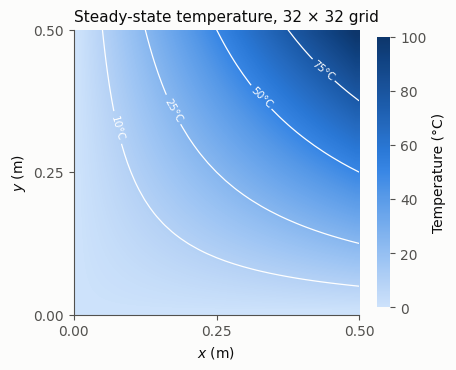

In [13]:
X, Y, w, n = PLATE_FINE
grid = np.linspace(0, 0.5, n + 1)
U = np.array([[plate_boundary(x, y) for x in grid] for y in grid])  # boundary values; interior overwritten
for x, y, value in zip(X, Y, w):
    U[int(round(y / 0.5 * n)), int(round(x / 0.5 * n))] = value

fig, ax = plt.subplots(figsize=(4.6, 3.9))
image = ax.imshow(U, origin="lower", extent=[0, 0.5, 0, 0.5], cmap=SEQUENTIAL, vmin=0, vmax=100,
                  interpolation="bilinear")
contours = ax.contour(grid, grid, U, levels=[10, 25, 50, 75], colors="white", linewidths=0.9)
ax.clabel(contours, fmt="%d°C", fontsize=7.5, colors="white")
colorbar = fig.colorbar(image, ax=ax, shrink=0.9)
colorbar.set_label("Temperature (°C)")
colorbar.outline.set_visible(False)
ax.set_xlabel("$x$ (m)")
ax.set_ylabel("$y$ (m)")
ax.set_xticks([0, 0.25, 0.5])
ax.set_yticks([0, 0.25, 0.5])
ax.set_title(f"Steady-state temperature, {n} × {n} grid", loc="left")

fig.savefig("figures/fig4_plate_temperature.pdf")
plt.show()

### Figure 5: Iterations as the grid is refined

Both axes are logarithmic, so growth like $n^2$ appears as a line of slope 2 and growth like $n$ as slope 1.

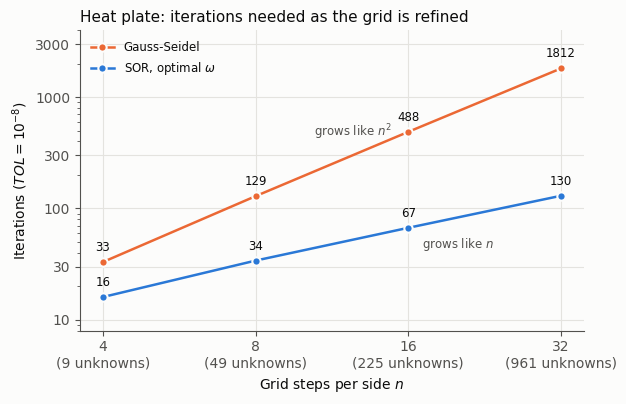

In [14]:
ns = np.array([row[0] for row in SCALING])
gs_iters = np.array([row[3] for row in SCALING])
sor_iters = np.array([row[4] for row in SCALING])

fig, ax = plt.subplots(figsize=(6.5, 3.9))
ax.grid(True, which="major")
for iters, color, label in [(gs_iters, ORANGE, "Gauss-Seidel"), (sor_iters, BLUE, r"SOR, optimal $\omega$")]:
    ax.plot(ns, iters, color=color, marker="o", markersize=6, markeredgecolor=SURFACE,
            markeredgewidth=1.5, label=label)
    for n_, k in zip(ns, iters):
        ax.annotate(str(k), (n_, k), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=8.5)

ax.annotate("grows like $n^2$", (ns[2], gs_iters[2]), xytext=(-12, 0), textcoords="offset points",
            ha="right", va="center", fontsize=8.5, color=INK_2)
ax.annotate("grows like $n$", (ns[2], sor_iters[2]), xytext=(10, -12), textcoords="offset points",
            ha="left", va="center", fontsize=8.5, color=INK_2)
ax.set_xscale("log", base=2)
ax.set_yscale("log")
ax.set_xticks(ns)
ax.set_xticklabels([f"{n_}\n({(n_ - 1) ** 2} unknowns)" for n_ in ns])
ax.set_yticks([10, 30, 100, 300, 1000, 3000])
ax.set_yticklabels(["10", "30", "100", "300", "1000", "3000"])
ax.set_ylim(8, 4000)
ax.set_xlabel("Grid steps per side $n$")
ax.set_ylabel("Iterations ($TOL = 10^{-8}$)")
ax.set_title("Heat plate: iterations needed as the grid is refined", loc="left")
ax.legend(loc="upper left", frameon=False, fontsize=8.5)

fig.savefig("figures/fig5_plate_scaling.pdf")
plt.show()